# Notebook 10 — Final robustness comparison, including the counter-example models  ·  GPU: T4

Run **after Notebooks 8 and 9**. *(v2: strips the "Answer:" prefix Instruct added to its rewrites — if an earlier run left such texts, they are fixed and only the affected scores are recomputed — and checks whether the counter-example model penalises real answers that merely contain a negation word.)* Uses the same 2 × 200 originals and rule-based variants as Notebook 6 (same exclusion rules as Notebook 7), and adds one **held-out** variant:

- `negated_llm`: Llama 3 8B Instruct rewrites the answer so it states the opposite, changing as few words as possible. This form was **never** used to build the training counter-examples, so it tests generalisation rather than memorised templates.

Every variant is scored by: fine-tuned (`ft`), fine-tuned + counter-examples (`ftaug`), Instruct zero-shot (calibrated for SciEntsBank), the 50/50 `ft`+Instruct ensemble, and the lexical system. The last section compares `ftaug` with `ft` on robustness **and** on the real test sets (paired, question-level bootstrap). Resumable; ≈ 50 min.

**Before running:** nothing new to upload. T4 runtime.

In [1]:
from google.colab import drive
drive.mount('/content/drive')
import os, sys
ROOT = '/content/drive/MyDrive/asag_revision'
sys.path.insert(0, ROOT)
!nvidia-smi --query-gpu=name --format=csv

Mounted at /content/drive
name
Tesla T4


In [2]:
!pip -q install -U bitsandbytes accelerate peft sentence-transformers language-tool-python

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 14.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 16.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 740.6/740.6 kB 19.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.2/63.2 kB 2.6 MB/s eta 0:00:00


In [3]:
import re, gc, warnings
import numpy as np, pandas as pd, torch, nltk
from tqdm.auto import tqdm
warnings.filterwarnings('ignore', message='This pattern is interpreted as a regular expression')
for p in ['stopwords', 'wordnet', 'omw-1.4', 'punkt', 'punkt_tab']:
    nltk.download(p, quiet=True)
from asag_utils import *
from llm_utils import *
from perturb import valid_pairs, negation_form, clean_paraphrase, META
RES = f'{ROOT}/results'
mo = pd.read_csv(f'{ROOT}/data/mohler_prepared.csv'); se = pd.read_csv(f'{ROOT}/data/scientsbank_prepared.csv')
LPM = [f'lp_{s}' for s in SCORE_TARGETS]; LPS = [f'lp_{l}' for l in LABEL_ORDER]
SET2 = {'mohler': f'{RES}/robustness2_set_mohler.csv', 'scientsbank': f'{RES}/robustness2_set_scientsbank.csv'}
OLD = {'mohler': f'{RES}/robustness_set.csv', 'scientsbank': f'{RES}/robustness_set_scientsbank.csv'}
def out(ds, system): return f'{RES}/robustness2_scores_{ds}_{system}.csv'
HAVE_SE_AUG = os.path.exists(f'{ROOT}/models/scientsbank_llama3_ftaug/adapter_config.json')
assert all(os.path.exists(f'{ROOT}/models/mohler_llama3_ftaug_f{k}/adapter_config.json') for k in range(N_FOLDS)), 'Run Notebook 8 first'
print('SciEntsBank counter-example model present:', HAVE_SE_AUG)

SciEntsBank counter-example model present: True


## 1. Held-out negations written by the Instruct model; everything else scored zero-shot

In [4]:
ANS = re.compile(r'^\s*answer\s*:\s*', re.I)
for ds in SET2:            # fix for v1 runs: Instruct prefixed most rewrites with "Answer:"
    if os.path.exists(SET2[ds]):
        rs2 = pd.read_csv(SET2[ds])
        m = (rs2.variant == 'negated_llm') & rs2.student_answer.astype(str).str.match(ANS)
        if m.any():
            rs2.loc[m, 'student_answer'] = rs2.loc[m, 'student_answer'].astype(str).str.replace(ANS, '', regex=True)
            rs2.to_csv(SET2[ds], index=False)
            for s_ in ['instruct_zs', 'ft', 'ftaug', 'lexical']:
                if os.path.exists(out(ds, s_)): os.remove(out(ds, s_))
            print(f'{ds}: removed "Answer:" from {m.sum()} LLM negations; all scores for this set will be recomputed')

NEG_PROMPT = ('Rewrite the following student answer so that it states the OPPOSITE of what it says (so that it '
              'contradicts the original), changing as few words as possible. Reply with the rewritten answer only.\n\nAnswer: {a}')
need_gen = [ds for ds in SET2 if not os.path.exists(SET2[ds])]
need_zs = [ds for ds in SET2 if not os.path.exists(out(ds, 'instruct_zs'))]
if need_gen or need_zs:
    model, tok = load_hf_4bit(INSTRUCT_MODEL)
    for ds in need_gen:
        rs = pd.read_csv(OLD[ds]); orig = rs[rs.variant == 'original']
        gens = []
        for i in tqdm(range(0, len(orig), 8), desc=f'negate {ds}'):
            batch = [tok.apply_chat_template([{'role': 'user', 'content': NEG_PROMPT.format(a=a)}], tokenize=False,
                                             add_generation_prompt=True) for a in orig.student_answer.astype(str).iloc[i:i + 8]]
            enc = tok(batch, return_tensors='pt', padding=True, add_special_tokens=False).to(model.device)
            with torch.no_grad():
                g = model.generate(**enc, max_new_tokens=160, do_sample=False, pad_token_id=tok.pad_token_id)
            gens += [ANS.sub('', clean_paraphrase(x)) for x in tok.batch_decode(g[:, enc.input_ids.shape[1]:], skip_special_tokens=True)]
        new = orig.copy(); new['variant'] = 'negated_llm'; new['student_answer'] = gens
        new['rid'] = [f'n{ds[0]}{i}' for i in range(len(new))]
        rs2 = pd.concat([rs, new], ignore_index=True); rs2.to_csv(SET2[ds], index=False)
        for o, n in list(zip(orig.student_answer, gens))[:4]:
            print('ORIG:', str(o)[:130]); print('NEG :', n[:130]); print()
    for ds in need_zs:
        rs2 = pd.read_csv(SET2[ds])
        words = SCORE_TARGETS if ds == 'mohler' else label_candidates(chat=True)
        cand, _ = candidate_ids(tok, words)
        lp = candidate_logprobs(model, tok, to_chat(tok, make_prompts(rs2, ds), INSTRUCT_PREFILL[ds]), cand,
                                batch_size=8, add_special_tokens=False)
        pd.concat([rs2[['rid']], pd.DataFrame(lp, columns=LPM if ds == 'mohler' else LPS)], axis=1).to_csv(out(ds, 'instruct_zs'), index=False)
    del model; gc.collect(); torch.cuda.empty_cache()
sets = {ds: pd.read_csv(SET2[ds]) for ds in SET2}

mohler: removed "Answer:" from 188 LLM negations; all scores for this set will be recomputed
scientsbank: removed "Answer:" from 190 LLM negations; all scores for this set will be recomputed


config.json:   0%|          | 0.00/1.26k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/51.1k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.09M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/345 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 5.70GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/220 [00:00<?, ?B/s]

224 4-bit layers; compute dtype before: ['torch.bfloat16'] -> torch.float16


## 2. Fine-tuned models, with and without counter-examples (one base model; adapters swapped)

In [5]:
jobs = [('mohler', 'ft'), ('mohler', 'ftaug'), ('scientsbank', 'ft')] + ([('scientsbank', 'ftaug')] if HAVE_SE_AUG else [])
jobs = [j for j in jobs if not os.path.exists(out(*j))]
if jobs:
    from peft import PeftModel
    model, tok = load_hf_4bit(BASE_MODEL); first = True
    def add(path, name):
        global model, first
        if first:
            model = PeftModel.from_pretrained(model, path, adapter_name=name); first = False
        else:
            model.load_adapter(path, adapter_name=name)
    for ds, sysname in jobs:
        rs2 = sets[ds]
        if ds == 'mohler':
            cand, _ = candidate_ids(tok, SCORE_TARGETS); parts = []
            for k in range(N_FOLDS):
                tag = 'llama3_ft' if sysname == 'ft' else 'llama3_ftaug'
                add(f'{ROOT}/models/mohler_{tag}_f{k}', f'{sysname}{k}'); model.set_adapter(f'{sysname}{k}'); model.eval()
                d = rs2[rs2.fold == k]
                lp = candidate_logprobs(model, tok, make_prompts(d, 'mohler'), cand, batch_size=8)
                parts.append(pd.concat([d[['rid']].reset_index(drop=True), pd.DataFrame(lp, columns=LPM)], axis=1))
            pd.concat(parts).to_csv(out(ds, sysname), index=False)
        else:
            cand, _ = candidate_ids(tok, label_candidates(chat=False))
            add(f'{ROOT}/models/scientsbank_llama3_{sysname}', f'se_{sysname}'); model.set_adapter(f'se_{sysname}'); model.eval()
            lp = candidate_logprobs(model, tok, make_prompts(rs2, 'scientsbank'), cand, batch_size=8)
            pd.concat([rs2[['rid']], pd.DataFrame(lp, columns=LPS)], axis=1).to_csv(out(ds, sysname), index=False)
        print('done', ds, sysname)
    del model; gc.collect(); torch.cuda.empty_cache()

config.json:   0%|          | 0.00/1.25k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/50.6k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.09M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 5.70GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/198 [00:00<?, ?B/s]

224 4-bit layers; compute dtype before: ['torch.bfloat16'] -> torch.float16
done mohler ft
done mohler ftaug
done scientsbank ft
done scientsbank ftaug


## 3. Lexical systems (as in Notebooks 0 and 6)

In [6]:
if not all(os.path.exists(out(ds, 'lexical')) for ds in sets):
    import language_tool_python
    from sentence_transformers import SentenceTransformer
    from sklearn.linear_model import LinearRegression, LogisticRegression
    from sklearn.preprocessing import StandardScaler
    from sklearn.pipeline import make_pipeline
    tool = language_tool_python.LanguageTool('en-US'); st = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2')
    feats = pd.read_csv(f'{ROOT}/cache/features.csv'); COMP = ['context', 'keyword', 'synonym', 'grammar']
    for ds, d in sets.items():
        L = d[['rid', 'reference_answer', 'student_answer']].copy()
        e1 = st.encode(L.reference_answer.astype(str).tolist(), normalize_embeddings=True, batch_size=64)
        e2 = st.encode(L.student_answer.astype(str).tolist(), normalize_embeddings=True, batch_size=64)
        L['context'] = context_score((e1 * e2).sum(1))
        L['keyword'] = [keyword_score(r, s) for r, s in zip(L.reference_answer, L.student_answer)]
        L['synonym'] = [synonym_score(r, s) for r, s in zip(L.reference_answer, L.student_answer)]
        L['grammar'] = [grammar_score(len(tool.check(str(s)))) for s in tqdm(L.student_answer, desc=f'grammar {ds}')]
        L['composite_fixed'] = composite_fixed(L)
        if ds == 'mohler':
            M = mo.merge(feats, on='uid'); L['score'] = np.nan
            for k in range(N_FOLDS):
                fit = M[M[f'split_f{k}'] != 'test']; lr = LinearRegression().fit(fit[['composite_fixed']], fit.y)
                idx = (d.fold == k).values
                L.loc[idx, 'score'] = np.clip(lr.predict(L.loc[idx, ['composite_fixed']]), 0, 10)
        else:
            S = se.merge(feats, on='uid'); fit = S[S.split.isin(['train', 'val'])]
            L['label_pred'] = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(fit[COMP], fit.label).predict(L[COMP])
        L.drop(columns=['reference_answer', 'student_answer']).to_csv(out(ds, 'lexical'), index=False)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

grammar mohler:   0%|          | 0/1400 [00:00<?, ?it/s]

grammar scientsbank:   0%|          | 0/1400 [00:00<?, ?it/s]

## 4. Robustness tables

In [7]:
from sklearn.linear_model import LogisticRegression
VARIANTS = ['negated:auxiliary', 'negated:prefix', 'negated_llm', 'keyword_salad', 'swapped', 'typos', 'paraphrase']

def boot_mean(values, groups, n_boot=2000, seed=SEED):
    values, groups = np.asarray(values, float), np.asarray(groups)
    s_ = [np.flatnonzero(groups == g) for g in pd.unique(groups)]; rng = np.random.default_rng(seed)
    b = [values[np.concatenate([s_[i] for i in rng.integers(0, len(s_), len(s_))])].mean() for _ in range(n_boot)]
    return np.percentile(b, 2.5), np.percentile(b, 97.5), min(1.0, max(2 * min((np.array(b) <= 0).mean(), (np.array(b) >= 0).mean()), 1 / n_boot))

def select(frame, v):
    base, form = (v.split(':') + [None])[:2]
    d = frame[(frame.variant == base) & frame.keep]
    return d[d.neg_form == form] if form else d

for ds, rs in sets.items():
    keep = valid_pairs(rs).values
    llm = (rs.variant == 'negated_llm').values
    orig_txt = rs.orig_uid.map(rs[rs.variant == 'original'].set_index('orig_uid').student_answer).astype(str)
    bad_llm = llm & (rs.student_answer.astype(str).str.contains(META).values | (rs.student_answer.astype(str) == orig_txt).values)
    rs['keep'] = keep & ~bad_llm
    rs['neg_form'] = orig_txt.map(negation_form)
    print(ds, 'excluded:', rs[~rs.keep].variant.value_counts().to_dict())

# ---------- Mohler
S = sets['mohler'][['rid', 'orig_uid', 'fold', 'group', 'variant', 'keep', 'neg_form']].copy()
for sysname in ['ft', 'ftaug', 'instruct_zs']:
    z = pd.read_csv(out('mohler', sysname)); e, _, _ = score_from_logprobs(z[LPM].values)
    S = S.merge(pd.DataFrame({'rid': z.rid, sysname: e}), on='rid')
S['ens_50_50'] = 0.5 * S.ft + 0.5 * S.instruct_zs
S = S.merge(pd.read_csv(out('mohler', 'lexical'))[['rid', 'score']].rename(columns={'score': 'lexical'}), on='rid')
SYS_M = ['ft', 'ftaug', 'instruct_zs', 'ens_50_50', 'lexical']
orig = S[S.variant == 'original'].set_index('orig_uid')
rows = []
for v in VARIANTS:
    d = select(S, v).set_index('orig_uid')
    for s in SYS_M:
        delta = d[s] - orig.loc[d.index, s]; lo, hi, _ = boot_mean(delta.values, d.group.values)
        rows.append({'variant': v, 'system': s, 'n': len(d), 'mean_delta': delta.mean(), 'ci': f'[{lo:.2f}, {hi:.2f}]',
                     'share_drop_ge3': (delta <= -3).mean(), 'share_abs_le1': (delta.abs() <= 1).mean()})
    diff = (d.ftaug - orig.loc[d.index, 'ftaug']) - (d.ft - orig.loc[d.index, 'ft'])
    lo, hi, p = boot_mean(diff.values, d.group.values)
    rows.append({'variant': v, 'system': 'ftaug − ft (paired)', 'n': len(d), 'mean_delta': diff.mean(), 'ci': f'[{lo:.2f}, {hi:.2f}]', 'p': p})
robM = pd.DataFrame(rows); robM.to_csv(f'{RES}/robustness2_summary_mohler.csv', index=False)
print('Mohler: mean change in score vs original (0-10)')
display(robM[robM.system.isin(SYS_M)].pivot_table(index='variant', columns='system', values='mean_delta').loc[VARIANTS, SYS_M].round(2))
display(robM[robM.system == 'ftaug − ft (paired)'][['variant', 'n', 'mean_delta', 'ci', 'p']].round(3))

mohler excluded: {'paraphrase': 49, 'typos': 9, 'negated_llm': 1}
scientsbank excluded: {'paraphrase': 29, 'typos': 8}
Mohler: mean change in score vs original (0-10)


system,ft,ftaug,instruct_zs,ens_50_50,lexical
variant,,,,,
negated:auxiliary,-1.25,-5.76,-2.64,-1.95,-0.10
negated:prefix,-3.09,-9.27,-6.95,-5.02,-0.09
negated_llm,-2.34,-4.44,-4.33,-3.34,-0.20
keyword_salad,0.21,-7.78,-2.42,-1.10,1.22
swapped,-4.29,-8.12,-7.60,-5.95,-2.35
typos,-0.13,-0.45,-0.77,-0.45,-0.85
paraphrase,-0.20,-0.18,0.09,-0.05,-0.12


,variant,n,mean_delta,ci,p
5,negated:auxiliary,99,-4.511,"[-5.54, -3.41]",0.000
11,negated:prefix,101,-6.188,"[-6.69, -5.74]",0.000
17,negated_llm,199,-2.102,"[-2.68, -1.58]",0.000
23,keyword_salad,200,-7.987,"[-8.88, -6.94]",0.000
29,swapped,200,-3.835,"[-4.27, -3.35]",0.000
35,typos,191,-0.318,"[-0.87, 0.02]",0.103
41,paraphrase,151,0.018,"[-0.05, 0.09]",0.638


In [8]:
# ---------- SciEntsBank
P = sets['scientsbank'][['rid', 'orig_uid', 'group', 'variant', 'keep', 'neg_form']].copy()
cal = pd.read_csv(f'{RES}/scientsbank_llama3_instruct_zs.csv').drop_duplicates('uid').merge(se[['uid', 'split', 'label']], on='uid')
cal = cal[cal.split.isin(['train', 'val'])]; qc, _, _ = labels_from_logprobs(cal[LPS].values)
zs_cal = LogisticRegression(max_iter=2000).fit(np.log(np.clip(qc, 1e-12, 1)), cal.label)
def aligned(clf, X):
    p = np.zeros((len(X), 5))
    for j, c in enumerate(clf.classes_): p[:, LABEL_ORDER.index(c)] = clf.predict_proba(X)[:, j]
    return p
Q = {}
for sysname in ['ft', 'ftaug', 'instruct_zs']:
    if os.path.exists(out('scientsbank', sysname)):
        z = pd.read_csv(out('scientsbank', sysname)).set_index('rid').loc[P.rid]
        q, _, _ = labels_from_logprobs(z[LPS].values)
        Q[sysname] = aligned(zs_cal, np.log(np.clip(q, 1e-12, 1))) if sysname == 'instruct_zs' else q
Q['ens_50_50'] = 0.5 * Q['ft'] + 0.5 * Q['instruct_zs']
for s, q in Q.items(): P[s] = np.array(LABEL_ORDER)[q.argmax(1)]
P = P.merge(pd.read_csv(out('scientsbank', 'lexical'))[['rid', 'label_pred']].rename(columns={'label_pred': 'lexical'}), on='rid')
SYS_S = [s for s in ['ft', 'ftaug', 'instruct_zs', 'ens_50_50', 'lexical'] if s in P]
rows = []
for v in ['original'] + VARIANTS:
    d = P[(P.variant == 'original')] if v == 'original' else select(P, v)
    for s in SYS_S:
        still = (d[s] == 'correct').astype(float); lo, hi, _ = boot_mean(still.values, d.group.values)
        rows.append({'variant': v, 'system': s, 'n': len(d), 'share_still_correct': still.mean(), 'ci': f'[{lo:.2f}, {hi:.2f}]',
                     'share_contradictory': (d[s] == 'contradictory').mean(),
                     'share_irrelevant_nondomain': d[s].isin(['irrelevant', 'non_domain']).mean()})
    if 'ftaug' in P:
        diff = (d.ftaug == 'correct').astype(float) - (d.ft == 'correct').astype(float)
        lo, hi, p = boot_mean(diff.values, d.group.values)
        rows.append({'variant': v, 'system': 'ftaug − ft (paired)', 'n': len(d), 'share_still_correct': diff.mean(),
                     'ci': f'[{lo:.2f}, {hi:.2f}]', 'p': p})
robS = pd.DataFrame(rows); robS.to_csv(f'{RES}/robustness2_summary_scientsbank.csv', index=False)
print("SciEntsBank: share still labelled 'correct'")
display(robS[robS.system.isin(SYS_S)].pivot_table(index='variant', columns='system', values='share_still_correct').loc[['original'] + VARIANTS, SYS_S].round(3))
display(robS[robS.system == 'ftaug − ft (paired)'][['variant', 'n', 'share_still_correct', 'ci', 'p']].round(3))

SciEntsBank: share still labelled 'correct'


system,ft,ftaug,instruct_zs,ens_50_50,lexical
variant,,,,,
original,0.720,0.730,0.760,0.725,0.860
negated:auxiliary,0.381,0.043,0.324,0.367,0.885
negated:prefix,0.148,0.000,0.066,0.115,0.787
negated_llm,0.150,0.060,0.150,0.140,0.785
keyword_salad,0.705,0.005,0.150,0.630,1.000
swapped,0.005,0.000,0.005,0.005,0.055
typos,0.698,0.729,0.656,0.714,0.688
paraphrase,0.696,0.678,0.813,0.731,0.825


,variant,n,share_still_correct,ci,p
5,original,200,0.010,"[-0.03, 0.06]",0.726
11,negated:auxiliary,139,-0.338,"[-0.43, -0.25]",0.000
17,negated:prefix,61,-0.148,"[-0.26, -0.06]",0.000
23,negated_llm,200,-0.090,"[-0.14, -0.05]",0.000
29,keyword_salad,200,-0.700,"[-0.81, -0.59]",0.000
35,swapped,200,-0.005,"[-0.02, 0.00]",0.712
41,typos,192,0.031,"[-0.01, 0.08]",0.185
47,paraphrase,171,-0.018,"[-0.07, 0.04]",0.612


## 5. Real test sets: counter-example model vs. fine-tuned (paired, question-level bootstrap)

In [9]:
def paired(y, a, b, fn, groups=None, n_boot=2000, seed=SEED):
    y, a, b = np.asarray(y), np.asarray(a), np.asarray(b); rng = np.random.default_rng(seed)
    s_ = None if groups is None else [np.flatnonzero(np.asarray(groups) == g) for g in pd.unique(groups)]
    ma, mb = fn(y, a), fn(y, b); D = []
    for _ in range(n_boot):
        i = rng.integers(0, len(y), len(y)) if s_ is None else np.concatenate([s_[j] for j in rng.integers(0, len(s_), len(s_))])
        A, B = fn(y[i], a[i]), fn(y[i], b[i]); D.append({k: A[k] - B[k] for k in A})
    D = pd.DataFrame(D)
    return {k: (ma[k] - mb[k], np.nanpercentile(D[k], 2.5), np.nanpercentile(D[k], 97.5),
                min(1.0, max(2 * min((D[k] <= 0).mean(), (D[k] >= 0).mean()), 1 / n_boot))) for k in ma}

pm = pd.read_csv(f'{RES}/mohler_preds.csv')
def low_band(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float); m = y < 6
    return {'signed_err_gold_lt6': (p[m] - y[m]).mean() if m.any() else np.nan, 'mae': np.abs(p - y).mean()}
rows = []
r = paired(pm.y, pm.llama3_ftaug, pm.llama3_ft, reg_metrics, groups=pm.group)
rows += [{'dataset': 'mohler', 'metric': k, 'diff': v[0], 'ci': f'[{v[1]:.3f}, {v[2]:.3f}]', 'p': v[3]} for k, v in r.items() if k in ('pearson', 'mae', 'qwk')]
r = paired(pm.y, pm.llama3_ftaug, pm.llama3_ft, low_band, groups=pm.group)['signed_err_gold_lt6']
rows.append({'dataset': 'mohler', 'metric': 'signed error, gold < 6', 'diff': r[0], 'ci': f'[{r[1]:.3f}, {r[2]:.3f}]', 'p': r[3]})
if HAVE_SE_AUG and os.path.exists(f'{RES}/scientsbank_llama3_ftaug.csv'):
    sp = pd.read_csv(f'{RES}/scientsbank_preds.csv')
    def contra_f1(y, p):
        y, p = np.asarray(y), np.asarray(p); tp = ((y == 'contradictory') & (p == 'contradictory')).sum()
        den = (y == 'contradictory').sum() + (p == 'contradictory').sum()
        return {'contradictory_f1': 2 * tp / den if den else np.nan}
    for t in ['test_ua', 'test_uq', 'test_ud']:
        d = sp[sp.split == t]; g = None if t == 'test_ua' else d.group
        for fn, keys in [(cls_metrics, ['macro_f1', 'weighted_f1']), (contra_f1, ['contradictory_f1'])]:
            r = paired(d.label, d.llama3_ftaug_5way, d.llama3_ft_5way, fn, groups=g)
            rows += [{'dataset': f'scientsbank {t}', 'metric': f'5-way {k}', 'diff': r[k][0],
                      'ci': f'[{r[k][1]:.3f}, {r[k][2]:.3f}]', 'p': r[k][3]} for k in keys]
# Does the counter-example model now punish REAL answers that merely contain a negation word?
from perturb import NEG_WORDS
negm = pm.merge(mo[['uid', 'student_answer']], on='uid')
negm = negm[negm.student_answer.astype(str).str.contains(NEG_WORDS)]
signed = lambda y, p: {'signed_error': float(np.mean(np.asarray(p, float) - np.asarray(y, float)))}
r = paired(negm.y, negm.llama3_ftaug, negm.llama3_ft, signed, groups=negm.group)['signed_error']
rows.append({'dataset': f'mohler, real answers containing a negation word (n={len(negm)})', 'metric': 'signed error',
             'diff': r[0], 'ci': f'[{r[1]:.3f}, {r[2]:.3f}]', 'p': r[3]})
if HAVE_SE_AUG and os.path.exists(f'{RES}/scientsbank_llama3_ftaug.csv'):
    spn = sp[sp.split.str.startswith('test')].merge(se[['uid', 'student_answer']], on='uid')
    spn = spn[spn.student_answer.astype(str).str.contains(NEG_WORDS) & (spn.label == 'correct')]
    fc = lambda y, p: {'false_contradictory_rate': float(np.mean(np.asarray(p) == 'contradictory'))}
    r = paired(spn.label, spn.llama3_ftaug_5way, spn.llama3_ft_5way, fc, groups=spn.group)['false_contradictory_rate']
    rows.append({'dataset': f'scientsbank, real CORRECT answers containing a negation word (n={len(spn)})',
                 'metric': "share wrongly labelled 'contradictory'", 'diff': r[0], 'ci': f'[{r[1]:.3f}, {r[2]:.3f}]', 'p': r[3]})
real = pd.DataFrame(rows); real.to_csv(f'{RES}/nb10_ftaug_vs_ft_real_tests.csv', index=False)
display(real.round(4))

,dataset,metric,diff,ci,p
0,mohler,pearson,0.0033,"[-0.034, 0.042]",0.832
1,mohler,mae,-0.0030,"[-0.076, 0.068]",0.905
2,mohler,qwk,0.0060,"[-0.029, 0.045]",0.704
3,mohler,"signed error, gold < 6",-0.3664,"[-0.729, -0.025]",0.038
4,scientsbank test_ua,5-way macro_f1,0.0994,"[-0.118, 0.207]",0.088
5,scientsbank test_ua,5-way weighted_f1,0.0258,"[-0.000, 0.053]",0.056
6,scientsbank test_ua,5-way contradictory_f1,-0.0066,"[-0.064, 0.047]",0.864
7,scientsbank test_uq,5-way macro_f1,0.0147,"[-0.015, 0.054]",0.335
8,scientsbank test_uq,5-way weighted_f1,0.0139,"[-0.018, 0.050]",0.442
9,scientsbank test_uq,5-way contradictory_f1,0.0456,"[-0.049, 0.127]",0.314


Positive `diff` favours the counter-example model for Pearson, QWK and F1; negative `diff` favours it for MAE and the signed error on weak answers. For the two negation-word rows, a diff near 0 is good (no new shortcut); a negative signed error or a positive false-contradictory rate would mean the model now punishes the word itself.

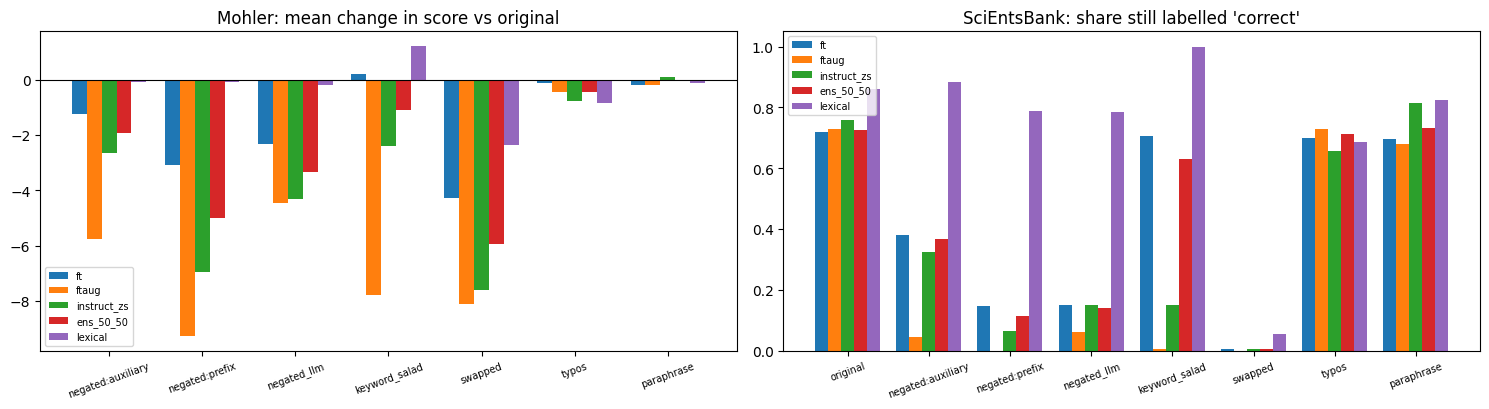

In [10]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(15, 4.2)); w = 0.16
for i, s in enumerate(SYS_M):
    d = robM[robM.system == s].set_index('variant').loc[VARIANTS]
    ax[0].bar(np.arange(len(VARIANTS)) + (i - 2) * w, d.mean_delta, w, label=s)
ax[0].axhline(0, color='k', lw=.8); ax[0].set_xticks(range(len(VARIANTS))); ax[0].set_xticklabels(VARIANTS, fontsize=7, rotation=20)
ax[0].set_title('Mohler: mean change in score vs original'); ax[0].legend(fontsize=7)
VS = ['original'] + VARIANTS
for i, s in enumerate(SYS_S):
    d = robS[robS.system == s].set_index('variant').loc[VS]
    ax[1].bar(np.arange(len(VS)) + (i - 2) * w, d.share_still_correct, w, label=s)
ax[1].set_xticks(range(len(VS))); ax[1].set_xticklabels(VS, fontsize=7, rotation=20)
ax[1].set_title("SciEntsBank: share still labelled 'correct'"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.savefig(f'{RES}/fig_robustness_final.png', dpi=300); plt.show()